### Encode Data for Tensor

In [1]:
import pandas as pd
from sodapy import Socrata
import numpy as np

from numpy import load

In [2]:
data = pd.read_excel('../Data/Internal/processed/2023IncidentDataClean.xlsx')

In [3]:
print(data)

                            railroadname  year incidentnumber  incidentyear  \
0            Alaska Railroad Corporation  2023        2023086            23   
1            Alaska Railroad Corporation  2023        2023111            23   
2                   BNSF Railway Company  2023      CA0223201            23   
3     Florida East Coast Railway Company  2023      X31071323            23   
4     Florida East Coast Railway Company  2023      X32072623            23   
...                                  ...   ...            ...           ...   
1363                  CSX Transportation  2023      000212582            23   
1364                  CSX Transportation  2023      000212837            23   
1365                  CSX Transportation  2023      000212120            23   
1366                  CSX Transportation  2023      000212966            23   
1367      Union Pacific Railroad Company  2023      0123RM025            23   

      incidentmonth maintainenanceincidentnumber  m

In [4]:
data = data.drop(columns=[ 'railroadname','year', 'incidentnumber', 'reportkey' ])


In [5]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1368 entries, 0 to 1367
Data columns (total 97 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   incidentyear                  1368 non-null   int64  
 1   incidentmonth                 1368 non-null   int64  
 2   maintainenanceincidentnumber  1364 non-null   object 
 3   maintenanceincidentyear       1364 non-null   float64
 4   maintenanceincidentmonth      1364 non-null   float64
 5   gradecrossingid               1368 non-null   object 
 6   date                          1368 non-null   object 
 7   month                         1368 non-null   int64  
 8   day                           1368 non-null   int64  
 9   hour                          1368 non-null   int64  
 10  minute                        1368 non-null   int64  
 11  ampm                          1368 non-null   object 
 12  time                          1368 non-null   object 
 13  cou

In [6]:
#for every column in the data, if colmn name contains 'code' collect it and seperate it from the data
#then drop the column from the data
codes = []
for col in data.columns:
    if 'code' in col:
        codes.append(data[col])
        data = data.drop(columns=[col])
    

In [7]:
print(data)

      incidentyear  incidentmonth maintainenanceincidentnumber  \
0               23              6                      2023086   
1               23              7                      2023111   
2               23              2                    CA0223201   
3               23              7                    X31071323   
4               23              7                    X32072623   
...            ...            ...                          ...   
1363            23              7                    000212582   
1364            23              8                    000212837   
1365            23              7                    000212120   
1366            23              8                    000212966   
1367            23              1                    0123RM025   

      maintenanceincidentyear  maintenanceincidentmonth gradecrossingid  \
0                        23.0                       6.0         868284G   
1                        23.0                       7.0  

In [8]:
print(codes)

[0       122.0
1       170.0
2        47.0
3       127.0
4        31.0
        ...  
1363     19.0
1364     79.0
1365     11.0
1366     45.0
1367     23.0
Name: countycode, Length: 1368, dtype: float64, 0        2
1        2
2        6
3       12
4       12
        ..
1363    54
1364    54
1365    54
1366    54
1367    56
Name: statecode, Length: 1368, dtype: int64, 0       Y
1       Y
2       Y
3       Y
4       N
       ..
1363    Y
1364    Y
1365    Y
1366    Y
1367    N
Name: publicprivatecode, Length: 1368, dtype: object, 0       A
1       A
2       A
3       K
4       C
       ..
1363    A
1364    C
1365    A
1366    A
1367    B
Name: highwayusercode, Length: 1368, dtype: object, 0       2.0
1       2.0
2       1.0
3       2.0
4       4.0
       ... 
1363    1.0
1364    1.0
1365    3.0
1366    3.0
1367    2.0
Name: vehicledirectioncode, Length: 1368, dtype: float64, 0       3.0
1       3.0
2       3.0
3       2.0
4       3.0
       ... 
1363    3.0
1364    2.0
1365    3.0
1366   

I know that the top 5 data points most frquently present between data points is 'crosswarningexpanded1', 'warningconnected signal', 'highwayuserposition', 'viewobstruction', 'weathercondition', 'visibility', 
Therefore, creating a matrix representing (crossing, crossing, crosswarningexpanded1, etc) would be interesting
In this data set, we have 1306 unique railroad crossing id's. 
Utilize tensor decomposition for clustering

In [9]:
crossingids = data['gradecrossingid'].unique()
print(len(crossingids))

1306


In [10]:
data['crossingwarningexpanded1'].unique()

array(['Crossbucks', 'Hwy. traffic signals', 'Gates', 'Stop signs',
       'None', 'Cantilever FLS', 'Standard FLS', 'Flagged by crew',
       'Other', 'Audible', 'Watchman', 'Wig wags'], dtype=object)

In [12]:
data['warningconnectedtosignal'].unique() 

array(['No', 'Yes', 'Unknown', nan], dtype=object)

In [13]:
data['highwayuserposition'].unique()

array(['Moving over crossing', 'Stopped on crossing',
       'Stalled or stuck on crossing', 'Trapped on crossing by traffic',
       'Blocked on crossing by gates', nan], dtype=object)

In [14]:
data['viewobstruction'].unique()

array(['Not obstructed', 'Passing train', 'Highway vehicles',
       'Standing railroad equipment', 'Other', 'Vegetation',
       'Permanent structure', 'Topography', nan], dtype=object)

In [15]:
data['weathercondition'].unique()

array(['Clear', 'Cloudy', 'Rain', 'Snow', 'Sleet', 'Fog', nan],
      dtype=object)

In [16]:
data['visibility'].unique()

array(['Day', 'Dusk', 'Dawn', 'Dark', nan], dtype=object)

In [17]:
import pandas as pd

# Sample data
crosswarning_data = {
    'crossingwarningexpanded1': ['Crossbucks', 'Hwy. traffic signals', 'Gates', 'Stop signs', 
                                 'None', 'Cantilever FLS', 'Standard FLS', 'Flagged by crew', 
                                 'Other', 'Audible', 'Watchman', 'Wig wags']
}
warningconnected_data = {
    'warningconnectedtosignal': ['No', 'Yes', 'Unknown', 'nan']
}
hwyuserpos_data = {
    'highwayuserposition': ['Moving over crossing', 'Stopped on crossing',
       'Stalled or stuck on crossing', 'Trapped on crossing by traffic',
       'Blocked on crossing by gates', 'nan']
}
view_data = {
    'viewobstruction': ['Not obstructed', 'Passing train', 'Highway vehicles',
       'Standing railroad equipment', 'Other', 'Vegetation',
       'Permanent structure', 'Topography', 'nan']
}
weather_data = {
    'weathercondition': ['Clear', 'Cloudy', 'Rain', 'Snow', 'Fog', 'Other', 'nan']
}
visibility_data = {
    'visibility': ['Daylight', 'Darkness', 'Darkness, lighted', 'Dawn', 'Dusk', 'Other', 'nan']
}

crosswarning_df = pd.DataFrame(crosswarning_data)
warningconnected_df = pd.DataFrame(warningconnected_data)
hwyuserpos_df = pd.DataFrame(hwyuserpos_data)
view_df = pd.DataFrame(view_data)
weather_df = pd.DataFrame(weather_data)
visibility_df = pd.DataFrame(visibility_data)


# Apply one-hot encoding
cross_one_hot_encoded_data = pd.get_dummies(crosswarning_df, columns=['crossingwarningexpanded1'])
warning_one_hot_encoded_data = pd.get_dummies(warningconnected_df, columns=['warningconnectedtosignal'])
hwyuserpos_one_hot_encoded_data = pd.get_dummies(hwyuserpos_df, columns=['highwayuserposition'])
view_one_hot_encoded_data = pd.get_dummies(view_df, columns=['viewobstruction'])
weather_one_hot_encoded_data = pd.get_dummies(weather_df, columns=['weathercondition'])
visibility_one_hot_encoded_data = pd.get_dummies(visibility_df, columns=['visibility'])

print(cross_one_hot_encoded_data)
print(warning_one_hot_encoded_data)
print(hwyuserpos_one_hot_encoded_data)
print(view_one_hot_encoded_data)
print(weather_one_hot_encoded_data)
print(visibility_one_hot_encoded_data)



    crossingwarningexpanded1_Audible  crossingwarningexpanded1_Cantilever FLS  \
0                                  0                                        0   
1                                  0                                        0   
2                                  0                                        0   
3                                  0                                        0   
4                                  0                                        0   
5                                  0                                        1   
6                                  0                                        0   
7                                  0                                        0   
8                                  0                                        0   
9                                  1                                        0   
10                                 0                                        0   
11                          

In [26]:
from sklearn.metrics import pairwise_distances
from scipy.spatial.distance import jaccard

# Assume `one_hot_encoded_data` is your DataFrame after one-hot encoding
# Compute the Jaccard dissimilarity (1 - Jaccard similarity) matrix
cross_dissimilarity_matrix = pairwise_distances(cross_one_hot_encoded_data, metric=jaccard)
warning_dissimilarity_matrix = pairwise_distances(warning_one_hot_encoded_data, metric=jaccard)
hwyuserpos_dissimilarity_matrix = pairwise_distances(hwyuserpos_one_hot_encoded_data, metric=jaccard)
view_dissimilarity_matrix = pairwise_distances(view_one_hot_encoded_data, metric=jaccard)
weather_dissimilarity_matrix = pairwise_distances(weather_one_hot_encoded_data, metric=jaccard)
visibility_dissimilarity_matrix = pairwise_distances(visibility_one_hot_encoded_data, metric=jaccard)


# Convert dissimilarity to similarity
cross_similarity_matrix = 1 - cross_dissimilarity_matrix
warning_similarity_matrix = 1 - warning_dissimilarity_matrix
hwyuserpos_similarity_matrix = 1 - hwyuserpos_dissimilarity_matrix
view_similarity_matrix = 1 - view_dissimilarity_matrix
weather_similarity_matrix = 1 - weather_dissimilarity_matrix
visibility_similarity_matrix = 1 - visibility_dissimilarity_matrix


# If you want to ignore the diagonal (self-similarity), you can set it to 0
np.fill_diagonal(cross_similarity_matrix, 0)
np.fill_diagonal(warning_similarity_matrix, 0)
np.fill_diagonal(hwyuserpos_similarity_matrix, 0)
np.fill_diagonal(view_similarity_matrix, 0)
np.fill_diagonal(weather_similarity_matrix, 0)

print(cross_dissimilarity_matrix)
print(warning_dissimilarity_matrix)
print(hwyuserpos_dissimilarity_matrix)
print(view_dissimilarity_matrix)
print(weather_dissimilarity_matrix)
print(visibility_dissimilarity_matrix)

print(cross_similarity_matrix)
print(warning_similarity_matrix)
print(hwyuserpos_similarity_matrix)
print(view_similarity_matrix)
print(weather_similarity_matrix)
print(visibility_similarity_matrix)



[[0. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
 [1. 0. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
 [1. 1. 0. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
 [1. 1. 1. 0. 1. 1. 1. 1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 0. 1. 1. 1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1. 0. 1. 1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1. 1. 0. 1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1. 1. 1. 0. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1. 1. 1. 1. 0. 1. 1. 1.]
 [1. 1. 1. 1. 1. 1. 1. 1. 1. 0. 1. 1.]
 [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 0. 1.]
 [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 0.]]
[[0. 1. 1. 1.]
 [1. 0. 1. 1.]
 [1. 1. 0. 1.]
 [1. 1. 1. 0.]]
[[0. 1. 1. 1. 1. 1.]
 [1. 0. 1. 1. 1. 1.]
 [1. 1. 0. 1. 1. 1.]
 [1. 1. 1. 0. 1. 1.]
 [1. 1. 1. 1. 0. 1.]
 [1. 1. 1. 1. 1. 0.]]
[[0. 1. 1. 1. 1. 1. 1. 1. 1.]
 [1. 0. 1. 1. 1. 1. 1. 1. 1.]
 [1. 1. 0. 1. 1. 1. 1. 1. 1.]
 [1. 1. 1. 0. 1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 0. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1. 0. 1. 1. 1.]
 [1. 1. 1. 1. 1. 1. 0. 1. 1.]
 [1. 1. 1. 1. 1. 1. 1. 0. 1.]
 [1. 1. 1. 1. 1. 1. 1. 1. 0.]]
[[0. 1. 1. 1. 1. 1. 1.]
 [1. 0. 1. 1. 1. 1. 1.]
 [1. 1. 0. 1. 1. 1. 1.]


In [27]:
print("Cross dissimialruty matrix shape:", cross_dissimilarity_matrix.shape)
print("Warning dissimialruty matrix shape:", warning_dissimilarity_matrix.shape)
print("Highway user position dissimialruty matrix shape:", hwyuserpos_dissimilarity_matrix.shape)
print("View obstruction dissimialruty matrix shape:", view_dissimilarity_matrix.shape)
print("Weather condition dissimialruty matrix shape:", weather_dissimilarity_matrix.shape)
print("Visibility dissimialruty matrix shape:", visibility_dissimilarity_matrix.shape)


Cross dissimialruty matrix shape: (12, 12)
Warning dissimialruty matrix shape: (4, 4)
Highway user position dissimialruty matrix shape: (6, 6)
View obstruction dissimialruty matrix shape: (9, 9)
Weather condition dissimialruty matrix shape: (7, 7)
Visibility dissimialruty matrix shape: (7, 7)


In [28]:
print("Cross matrix shape:", cross_similarity_matrix.shape)
print("Warning matrix shape:", warning_similarity_matrix.shape)
print("Highway user position matrix shape:", hwyuserpos_similarity_matrix.shape)
print("View obstruction matrix shape:", view_similarity_matrix.shape)
print("Weather condition matrix shape:", weather_similarity_matrix.shape)
print("Visibility matrix shape:", visibility_similarity_matrix.shape)



Cross matrix shape: (12, 12)
Warning matrix shape: (4, 4)
Highway user position matrix shape: (6, 6)
View obstruction matrix shape: (9, 9)
Weather condition matrix shape: (7, 7)
Visibility matrix shape: (7, 7)


In [96]:
def expand_matrix(matrix, target_size=12):
    current_size = matrix.shape[0]
    if current_size < target_size:
        expanded_matrix = np.zeros((target_size, target_size))
        expanded_matrix[:current_size, :current_size] = matrix
        return expanded_matrix
    else:
        return matrix

cross_expanded = expand_matrix(cross_similarity_matrix)
warning_expanded = expand_matrix(warning_similarity_matrix)
highway_user_pos_expanded = expand_matrix(hwyuserpos_similarity_matrix)
view_obstruction_expanded = expand_matrix(view_similarity_matrix)
weather_condition_expanded = expand_matrix(weather_similarity_matrix)
visibility_expanded = expand_matrix(visibility_similarity_matrix)

print(cross_expanded)
print(warning_expanded)
print(highway_user_pos_expanded)
print(view_obstruction_expanded)
print(weather_condition_expanded)
print(visibility_expanded)


[[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]]
[[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]]
[[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 

In [97]:
tensor_X = np.stack([cross_expanded, warning_expanded, highway_user_pos_expanded, 
                     view_obstruction_expanded, weather_condition_expanded, 
                     visibility_expanded], axis=-1)


In [99]:
tensor_X.shape

(12, 12, 6)

In [41]:

# Stack the similarity matrices to form a 3D tensor
similartiy_tensor = np.stack([weather_similarity_matrix, visibility_similarity_matrix], axis=-1)
dissim_tensor = np.stack([weather_dissimilarity_matrix, visibility_dissimilarity_matrix], axis=-1)

In [39]:
import tensorly as tl
import matplotlib.pyplot as plt
from tensorly.regression.cp_regression import CPRegressor
from tensorly.decomposition import parafac




In [100]:
# Perform CP decomposition
factors = parafac(tensor_X, rank=3)

# Choose one factor matrix as the clustering input
clustering_input = factors[0]  # This is an example; the choice depends on your specific data and needs
clustering_input = clustering_input.reshape(-1, 1)

# Proceed with clustering on this input
kmeans = KMeans(n_clusters=3)
clusters = kmeans.fit_predict(clustering_input)


LinAlgError: Singular matrix

In [83]:
clusters

array([0, 0, 0], dtype=int32)

In [84]:
kmeans

KMeans(n_clusters=3)

IndexError: index 1 is out of bounds for axis 1 with size 1

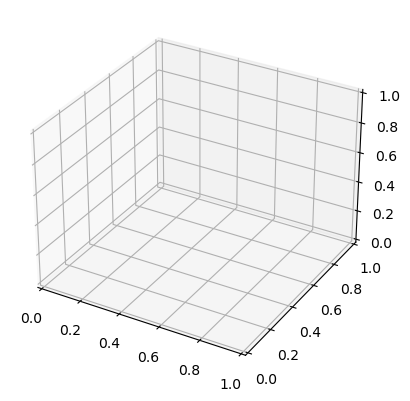

In [85]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

# Scatter plot using the three components
ax.scatter(clustering_input[:, 0], clustering_input[:, 1], clustering_input[:, 2], c=clusters, cmap='viridis')

ax.set_xlabel('Component 1')
ax.set_ylabel('Component 2')
ax.set_zlabel('Component 3')
plt.title('3D Cluster Visualization')
plt.show()


/Users/hugobaca/anaconda3/lib/python3.11/site-packages/sklearn/decomposition/_pca.py:543: RuntimeWarning: invalid value encountered in divide
  explained_variance_ratio_ = explained_variance_ / total_var


IndexError: index 1 is out of bounds for axis 1 with size 1

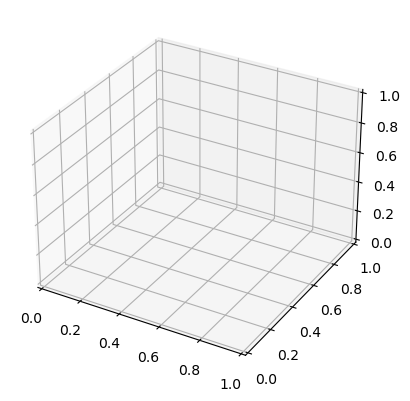

In [91]:
from sklearn.decomposition import PCA

# Reduce to three dimensions
pca = PCA(n_components=1)
reduced_data = pca.fit_transform(clustering_input)

# 3D Plot
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

ax.scatter(reduced_data[:, 0], reduced_data[:, 1], reduced_data[:, 2], c=clusters, cmap='viridis')

ax.set_xlabel('PCA 1')
ax.set_ylabel('PCA 2')
ax.set_zlabel('PCA 3')
plt.title('3D Cluster Visualization after PCA')
plt.show()


In [93]:
clustering_input.shape

(3, 1)

In [92]:
import matplotlib.pyplot as plt

# Assuming clustering_input has two dimensions
if clustering_input.shape[1] == 2:
    plt.scatter(clustering_input[:, 0], clustering_input[:, 1], c=clusters, cmap='viridis')
    plt.xlabel('Dimension 1')
    plt.ylabel('Dimension 2')
    plt.title('2D Cluster Visualization')
    plt.show()
else:
    print("The data does not have the required dimensions for this plot.")


The data does not have the required dimensions for this plot.


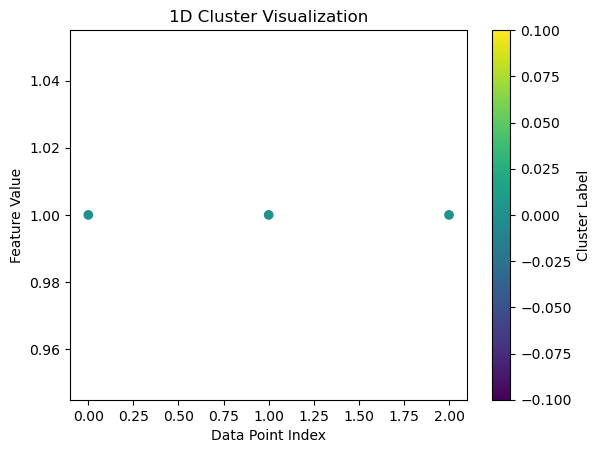

In [94]:
import matplotlib.pyplot as plt

# Assuming clusters is the array of cluster labels
plt.scatter(range(len(clusters)), clustering_input[:, 0], c=clusters, cmap='viridis')
plt.xlabel('Data Point Index')
plt.ylabel('Feature Value')
plt.title('1D Cluster Visualization')
plt.colorbar(label='Cluster Label')
plt.show()
